In [1]:
# import sys
# !{sys.executable} -m pip install --upgrade zarr
# !{sys.executable} -m pip install --upgrade c-lasso 

from classo import random_data, classo_problem
import numpy as np
import matplotlib.pyplot as plt
from copy import deepcopy

## Data 

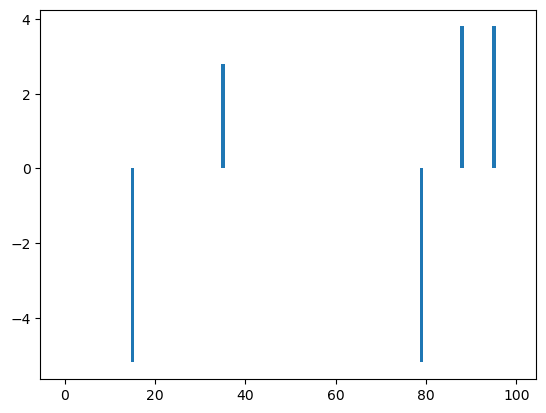

array([15, 35, 79, 88, 95])

In [2]:
m, d, d_nonzero, k, sigma = 150, 100, 5, 1, 0.5
(X, C, y), sol = random_data(m, d, d_nonzero, k, sigma, zerosum = True, seed = 0)
plt.bar(range(len(sol)), sol)
plt.show()

np.arange(len(sol))[sol != 0.]

In [3]:
print("lambdamax = ", max(abs(X.T.dot(y))))

lambdamax =  794.0396253503022


## Problems

In [4]:
problem = classo_problem(X, y+0.5, C= C)
problem.model_selection.PATH = True
problem.model_selection.CV = True
problem.model_selection.StabSel = True
problem.model_selection.LAMfixed = True


problem1 = deepcopy(problem)
problem2 = deepcopy(problem)
problem3 = deepcopy(problem)

problem2.formulation.w = np.array([1.1]*40+ [1.]*(d-40))


problem1.formulation.intercept = True
problem2.formulation.intercept = True
problem3.formulation.intercept = False

In [5]:
y

array([ -3.68394737,  -5.62561733,   1.2955375 ,  -0.65971498,
        -6.20591639,  -8.44563805,   0.36249462, -14.33070376,
        12.31583391,   0.91496394,   7.74426305,  -7.50820601,
        -9.40255435, -11.28811669,  27.64149375,   5.09998597,
         5.84928217,   7.14028945,   0.07212997,   5.07990701,
         1.67637415,  -1.18748249,  16.29050567, -14.98244939,
        -3.75960241,   6.06761267,   3.01989008,   8.09662375,
        12.33197441,  10.08743912,  -1.66714103,   3.98767188,
       -15.4655544 ,   9.46890466,   7.32219472, -16.78292718,
         0.20386708,  -9.11219699,   6.4751097 ,   2.12360558,
        16.63062502,  13.6569195 ,  16.43396577,   0.48911078,
         1.9828879 ,  -3.5611444 ,   6.47261057, -15.11116712,
       -14.5943713 ,  12.05919484,   1.15763175,   7.6744423 ,
        -9.00514051, -21.59073612,  13.82896107,  -7.26596329,
        -6.70620896,   2.70609257,   0.81403619,  -0.49999394,
         2.71638166,   7.83483841,   1.54538036,  -3.74

### Path 

In [6]:
param = problem1.model_selection.PATHparameters
param.numerical_method = ' '
param.n_active = 20
param.lambdas = np.linspace(1., 1e-3, 50)

In [7]:
param = problem2.model_selection.PATHparameters
param.numerical_method = 'P-PDS'
param.n_active = 0
param.lambdas = np.linspace(1., 1e-1, 50)

In [8]:
param = problem3.model_selection.PATHparameters
param.numerical_method = 'DR'
param.n_active = 0
param.lambdas = np.linspace(1., 1e-1, 20)

### Cross validation 

In [9]:
param = problem1.model_selection.CVparameters
param.seed = None
param.numerical_method = ' '
param.Nsubset = 5
param.oneSE = True
param.lambdas = np.linspace(1., 1e-3, 80)

In [10]:
param = problem2.model_selection.CVparameters
param.seed = None
param.numerical_method = ' '
param.Nsubset = 7
param.oneSE = False
param.lambdas = np.linspace(1., 1e-3, 80)

In [11]:
param = problem3.model_selection.CVparameters
param.seed = 2
param.numerical_method = 'P-PDS'
param.Nsubset = 3
param.oneSE = True
param.lambdas = np.linspace(1., 1e-1, 20)

### Stability Selection

In [12]:
param = problem1.model_selection.StabSelparameters
param.seed = None
param.numerical_method = ' '
param.method = 'first'
param.B = 50
param.q = 10
param.percent_nS = 0.5
param.lamin = 0.01
param.hd = False
param.lam = 'theoretical'
param.true_lam = True
param.threshold = 0.7 
param.threshold_label = 0.2

In [13]:
param = problem2.model_selection.StabSelparameters
param.seed = None
param.numerical_method = ' '
param.method = 'max'
param.B = 70
param.q = 20
param.percent_nS = 0.8
param.lamin = 0.01
param.hd = False
param.lam = 'theoretical'
param.true_lam = True
param.threshold = 0.5 
param.threshold_label = 0.2

In [14]:
param = problem3.model_selection.StabSelparameters
param.seed = None
param.numerical_method = ' '
param.method = 'lam'
param.B = 50
param.q = 1000
param.percent_nS = 0.4
param.lamin = 1.
param.hd = False
param.lam = 'theoretical'
param.true_lam = True
param.threshold = 0.8
param.threshold_label = 0.2

### Lambda fixed 

In [15]:
param = problem1.model_selection.LAMfixedparameters
param.numerical_method = 'P-PDS'
param.lam = 'theoretical'
param.true_lam = True

In [16]:
param = problem2.model_selection.LAMfixedparameters
param.numerical_method = 'DR'
param.lam = 0.1
param.true_lam = False

In [17]:
param = problem3.model_selection.LAMfixedparameters
param.numerical_method = ' '
param.lam = 0.
param.true_lam = True

## R1

In [18]:
problem1.formulation.concomitant = False
problem1.formulation.huber = False
problem1.formulation.classification = False

problem2.formulation.concomitant = False
problem2.formulation.huber = False
problem2.formulation.classification = False

problem3.formulation.concomitant = False
problem3.formulation.huber = False
problem3.formulation.classification = False

 
 
FORMULATION: R1
 
MODEL SELECTION COMPUTED:  
     Path
     Cross Validation
     Stability selection
     Lambda fixed
 
LAMBDA FIXED PARAMETERS: 
     numerical_method = P-PDS
     rescaled lam : True
     threshold = 0.173
     lam : theoretical
     theoretical_lam = 0.1628
 
PATH PARAMETERS: 
     numerical_method : Path-Alg
     lamin = 0.001
     Nlam = 50
      
     maximum active variables = 20
 
CROSS VALIDATION PARAMETERS: 
     numerical_method : Path-Alg
     one-SE method : True
     Nsubset = 5
     lamin = 0.001
     Nlam = 80
      
 
STABILITY SELECTION PARAMETERS: 
     numerical_method : Path-Alg
     method : first
     B = 50
     q = 10
     percent_nS = 0.5
     threshold = 0.7
     lamin = 0.01
     Nlam = 50



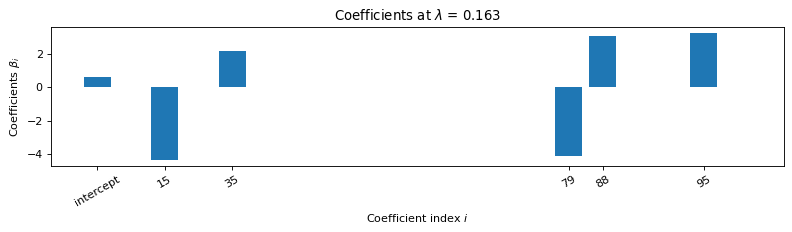

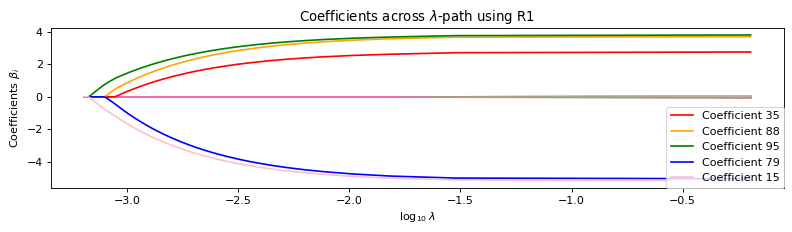

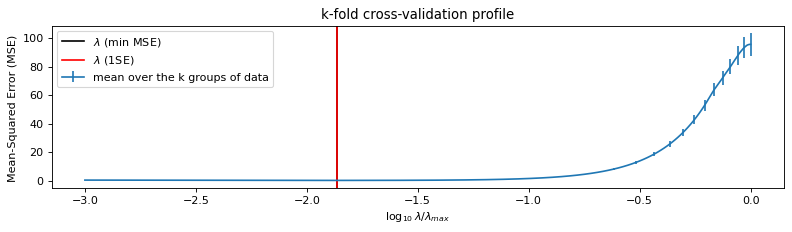

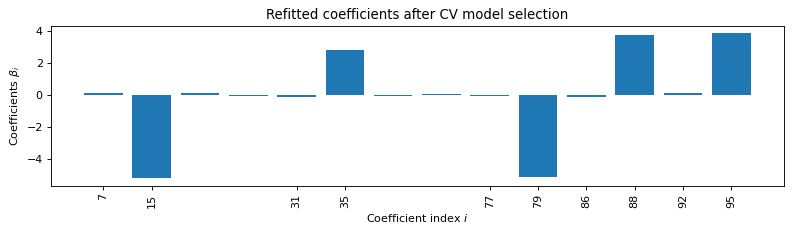

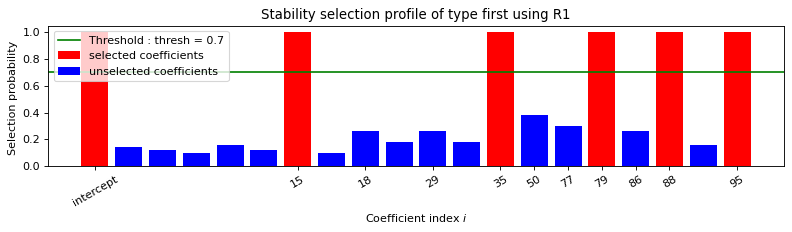

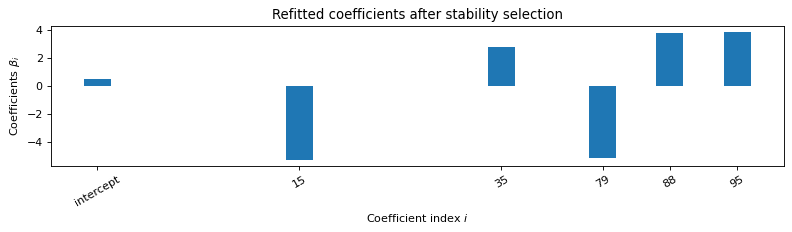


 LAMBDA FIXED : 
   Selected variables :  intercept    15    35    79    88    95    
   Running time :  0.004s

 PATH COMPUTATION : 
   There is also an intercept.  
   Running time :  0.005s

 CROSS VALIDATION : 
    Intercept : 0.4837866845275704
   Selected variables :  7    15    25    29    31    35    50    69    77    79    86    88    92    95    
   Running time :  0.115s

 STABILITY SELECTION : 
   Selected variables :  intercept    15    35    79    88    95    
   Running time :  0.124s

 
 
FORMULATION: R1
 
MODEL SELECTION COMPUTED:  
     Path
     Cross Validation
     Stability selection
     Lambda fixed
 
LAMBDA FIXED PARAMETERS: 
     numerical_method = DR
     rescaled lam : True
     threshold = 0.189
     lam = 0.1
     theoretical_lam = 0.1628
 
PATH PARAMETERS: 
     numerical_method : P-PDS
     lamin = 0.1
     Nlam = 50
      
 
CROSS VALIDATION PARAMETERS: 
     numerical_method : Path-Alg
     one-SE method : False
     Nsubset = 7
     lamin = 0.001
   

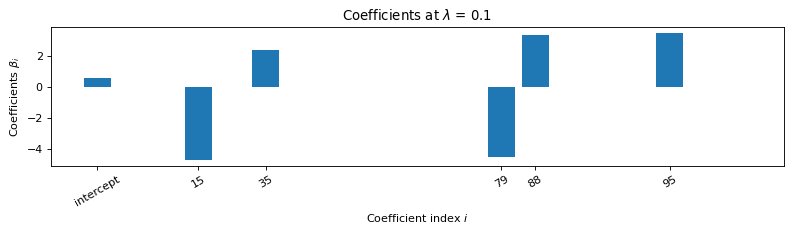

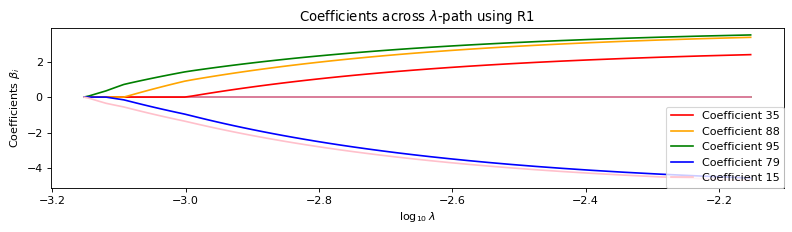

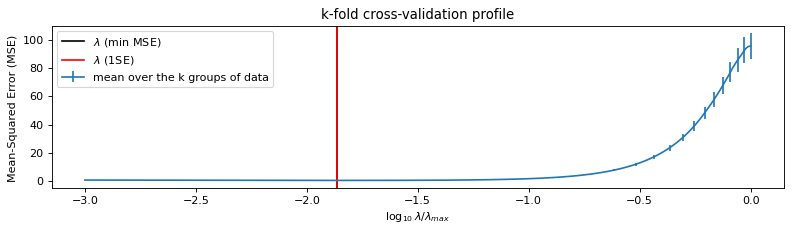

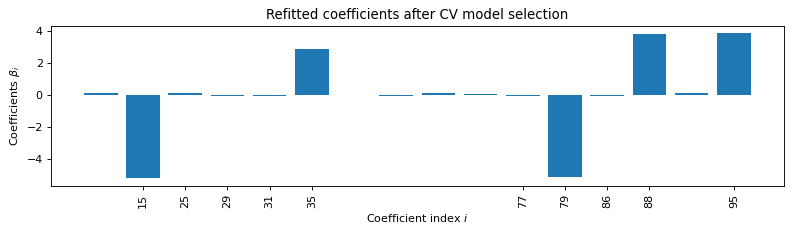

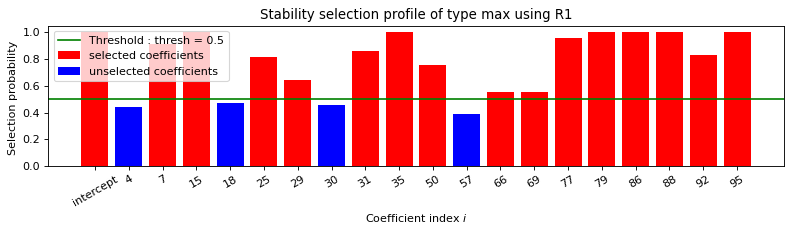

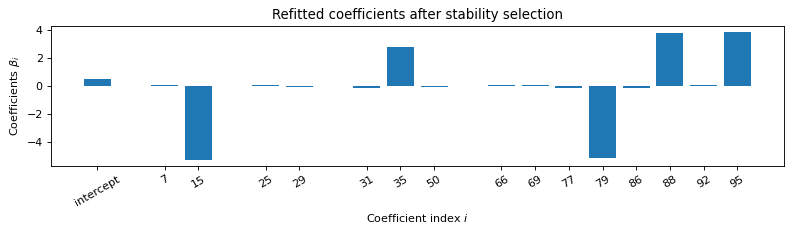


 LAMBDA FIXED : 
   Selected variables :  intercept    15    35    79    88    95    
   Running time :  0.035s

 PATH COMPUTATION : 
   There is also an intercept.  
   Running time :  0.057s

 CROSS VALIDATION : 
    Intercept : 0.486283965762238
   Selected variables :  7    15    25    29    31    35    50    55    66    69    77    79    86    88    92    95    
   Running time :  0.151s

 STABILITY SELECTION : 
   Selected variables :  intercept    7    15    25    29    31    35    50    66    69    77    79    86    88    92    95    
   Running time :  0.392s

 
 
FORMULATION: R1
 
MODEL SELECTION COMPUTED:  
     Path
     Cross Validation
     Stability selection
     Lambda fixed
 
LAMBDA FIXED PARAMETERS: 
     numerical_method = DR
     rescaled lam : True
     threshold = 0.276
     lam = 0.0
     theoretical_lam = 0.1628
 
PATH PARAMETERS: 
     numerical_method : DR
     lamin = 0.1
     Nlam = 20
      
 
CROSS VALIDATION PARAMETERS: 
     numerical_method : P-PDS
  

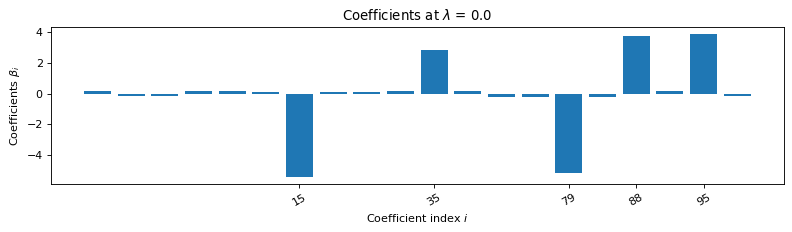

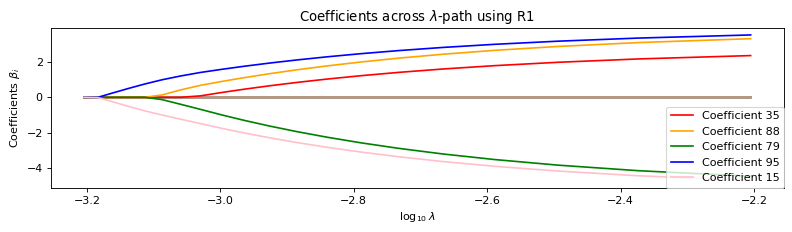

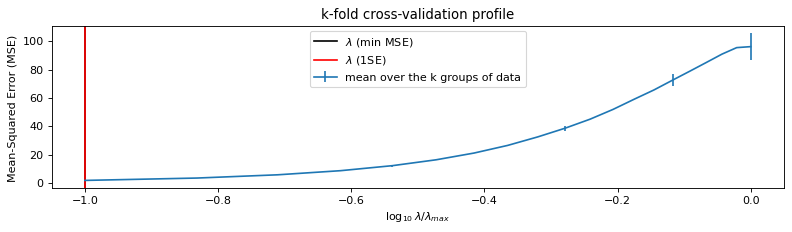

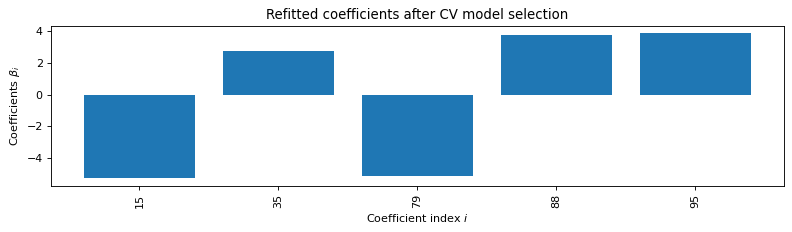

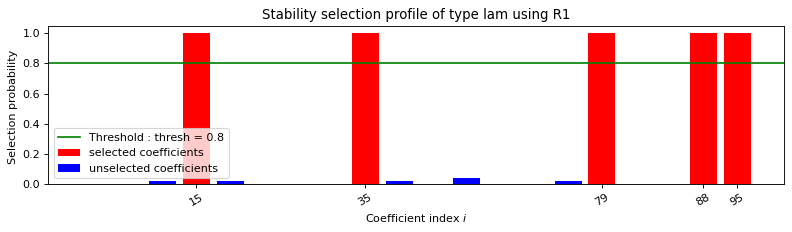

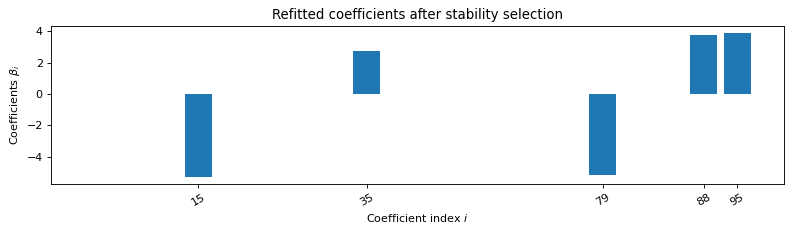


 LAMBDA FIXED : 
   Selected variables :  15    35    79    88    95    
   Running time :  0.006s

 PATH COMPUTATION : 
   Running time :  0.316s

 CROSS VALIDATION : 
   Selected variables :  15    35    79    88    95    
   Running time :  0.088s

 STABILITY SELECTION : 
   Selected variables :  15    35    79    88    95    
   Running time :  0.048s



In [19]:
problem1.solve()
print(problem1)
print(problem1.solution)

problem2.solve()
print(problem2)
print(problem2.solution)


problem3.solve()
print(problem3)
print(problem3.solution)


## Reset the numerical methods 

In [20]:
problem1.model_selection.PATHparameters.numerical_method = ' '
problem2.model_selection.PATHparameters.numerical_method = 'P-PDS'
problem3.model_selection.PATHparameters.numerical_method = 'DR'

problem1.model_selection.CVparameters.numerical_method = ' '
problem2.model_selection.CVparameters.numerical_method = ' '
problem3.model_selection.CVparameters.numerical_method = 'P-PDS' 

problem1.model_selection.StabSelparameters.numerical_method = ' '
problem2.model_selection.StabSelparameters.numerical_method = ' '
problem3.model_selection.StabSelparameters.numerical_method = ' '

problem3.model_selection.StabSelparameters.lam = 'theoretical'

problem1.model_selection.LAMfixedparameters.numerical_method = 'P-PDS'
problem2.model_selection.LAMfixedparameters.numerical_method = 'DR'
problem3.model_selection.LAMfixedparameters.numerical_method = 'Path-Alg'

problem1.model_selection.LAMfixedparameters.lam = 'theoretical'

## R2

In [21]:
problem1.formulation.concomitant = False
problem1.formulation.huber = True
problem1.formulation.classification = False

problem2.formulation.concomitant = False
problem2.formulation.huber = True
problem2.formulation.classification = False

problem3.formulation.concomitant = False
problem3.formulation.huber = True
problem3.formulation.classification = False

too many labels, there for the labels ['0'] have been deleted
 
 
FORMULATION: R2
 
MODEL SELECTION COMPUTED:  
     Path
     Cross Validation
     Stability selection
     Lambda fixed
 
LAMBDA FIXED PARAMETERS: 
     numerical_method = P-PDS
     rescaled lam : True
     threshold = 0.173
     lam : theoretical
     theoretical_lam = 0.1628
 
PATH PARAMETERS: 
     numerical_method : Path-Alg
     lamin = 0.001
     Nlam = 50
      
     maximum active variables = 20
 
CROSS VALIDATION PARAMETERS: 
     numerical_method : Path-Alg
     one-SE method : True
     Nsubset = 5
     lamin = 0.001
     Nlam = 80
      
 
STABILITY SELECTION PARAMETERS: 
     numerical_method : Path-Alg
     method : first
     B = 50
     q = 10
     percent_nS = 0.5
     threshold = 0.7
     lamin = 0.01
     Nlam = 50



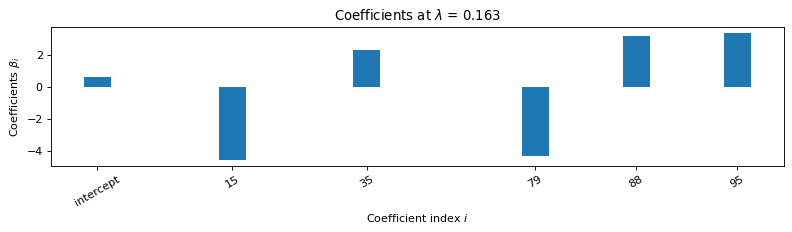

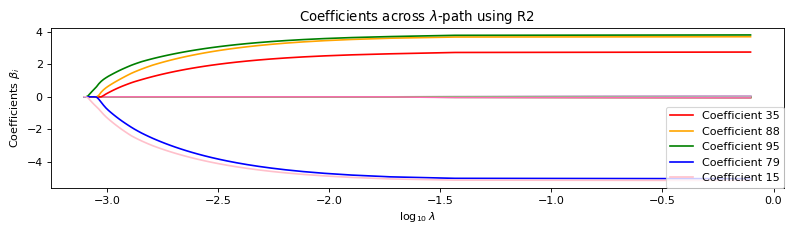

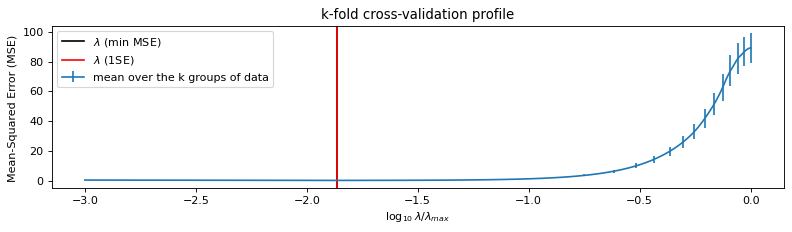

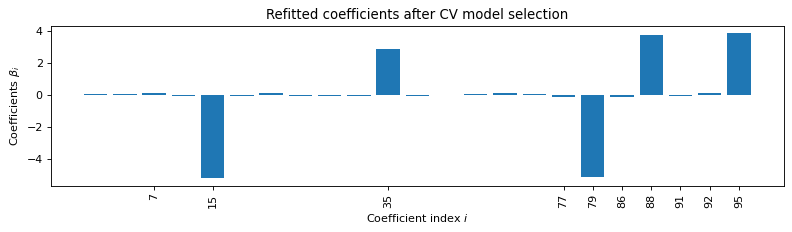

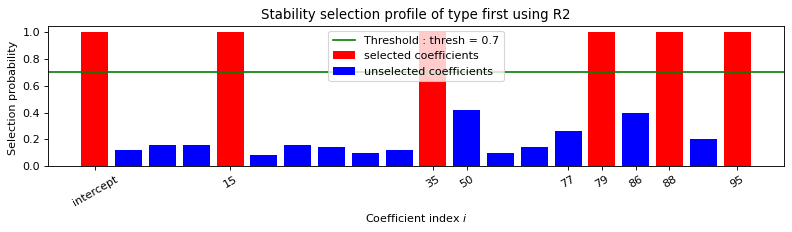

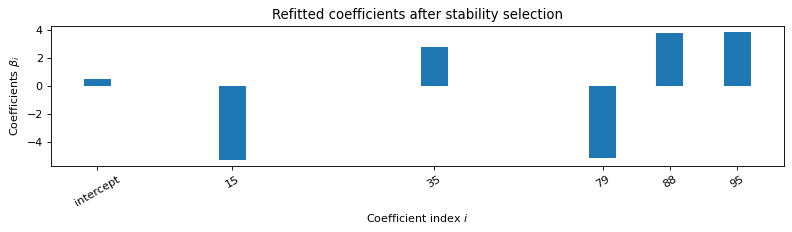


 LAMBDA FIXED : 
   Selected variables :  intercept    15    35    79    88    95    
   Running time :  0.005s

 PATH COMPUTATION : 
   There is also an intercept.  
   Running time :  0.026s

 CROSS VALIDATION : 
    Intercept : 0.4955049362158183
   Selected variables :  0    4    7    11    15    18    25    29    30    31    35    50    55    57    66    69    77    79    86    88    91    92    95    
   Running time :  0.285s

 STABILITY SELECTION : 
   Selected variables :  intercept    15    35    79    88    95    
   Running time :  0.498s

too many labels, there for the labels ['0'] have been deleted
 
 
FORMULATION: R2
 
MODEL SELECTION COMPUTED:  
     Path
     Cross Validation
     Stability selection
     Lambda fixed
 
LAMBDA FIXED PARAMETERS: 
     numerical_method = DR
     rescaled lam : True
     threshold = 0.189
     lam = 0.1
     theoretical_lam = 0.1628
 
PATH PARAMETERS: 
     numerical_method : P-PDS
     lamin = 0.1
     Nlam = 50
      
 
CROSS VALIDATIO

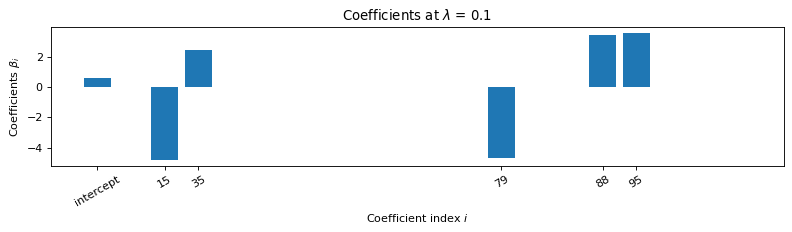

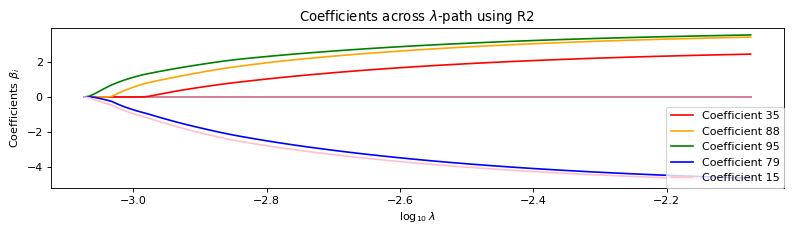

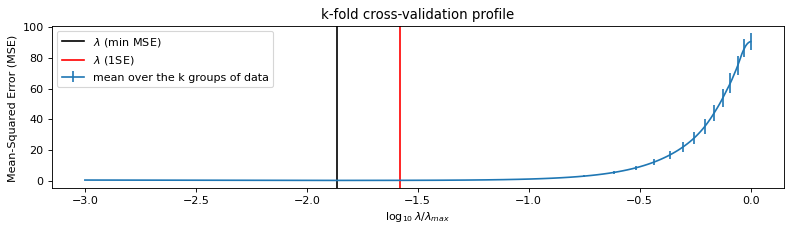

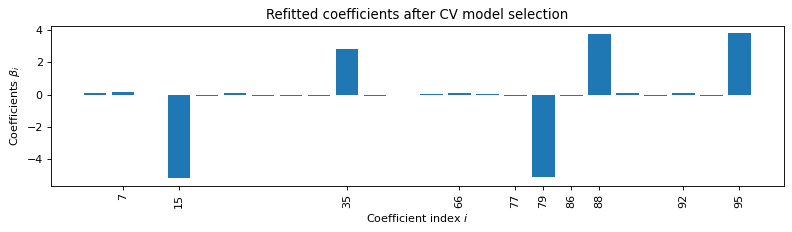

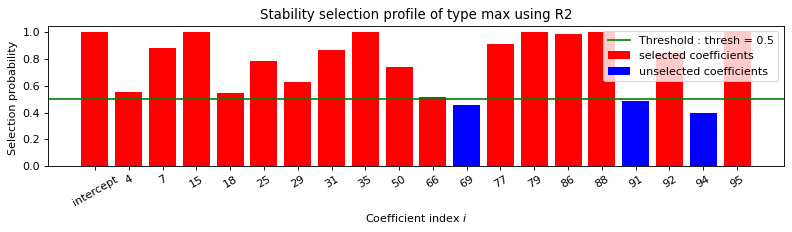

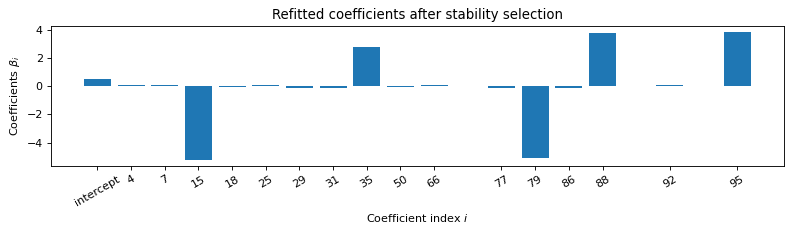


 LAMBDA FIXED : 
   Selected variables :  intercept    15    35    79    88    95    
   Running time :  0.069s

 PATH COMPUTATION : 
   There is also an intercept.  
   Running time :  0.165s

 CROSS VALIDATION : 
    Intercept : 0.4901788318293437
   Selected variables :  4    7    11    15    18    25    29    30    31    35    50    55    57    66    69    77    79    86    88    89    91    92    94    95    
   Running time :  0.403s

 STABILITY SELECTION : 
   Selected variables :  intercept    4    7    15    18    25    29    31    35    50    66    77    79    86    88    92    95    
   Running time :  1.753s

 
 
FORMULATION: R2
 
MODEL SELECTION COMPUTED:  
     Path
     Cross Validation
     Stability selection
     Lambda fixed
 
LAMBDA FIXED PARAMETERS: 
     numerical_method = Path-Alg
     rescaled lam : True
     threshold = 0.276
     lam = 0.0
     theoretical_lam = 0.1628
 
PATH PARAMETERS: 
     numerical_method : DR
     lamin = 0.1
     Nlam = 20
      
 
CRO

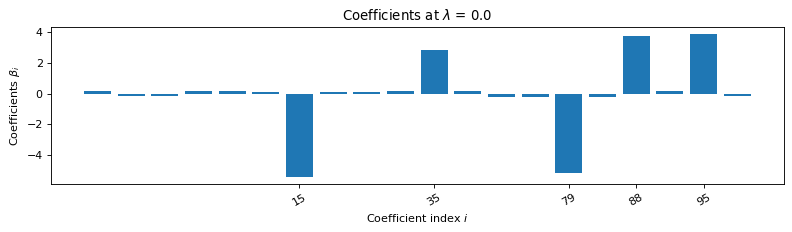

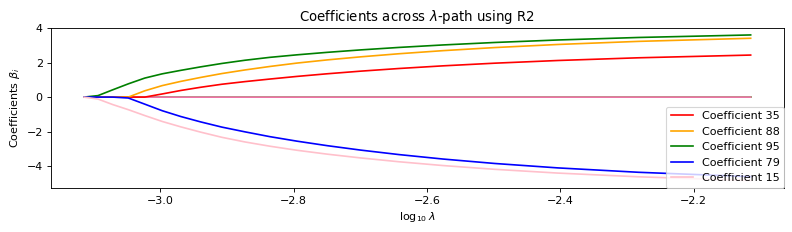

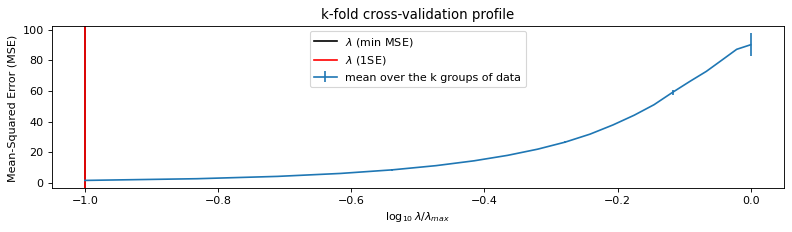

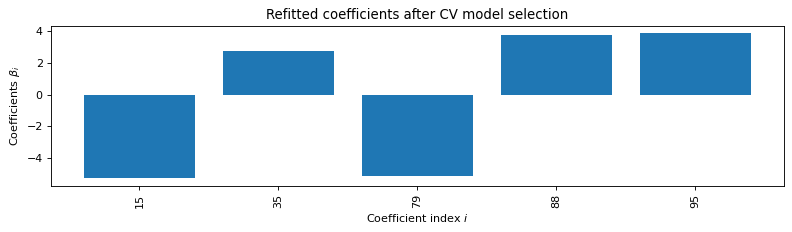

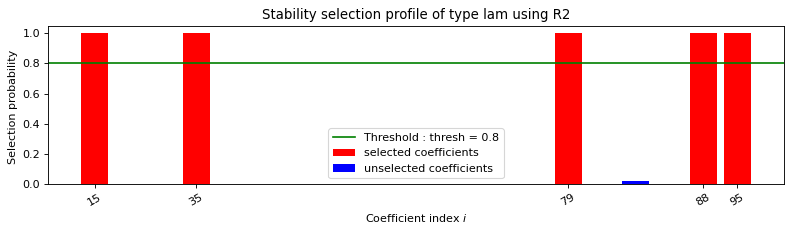

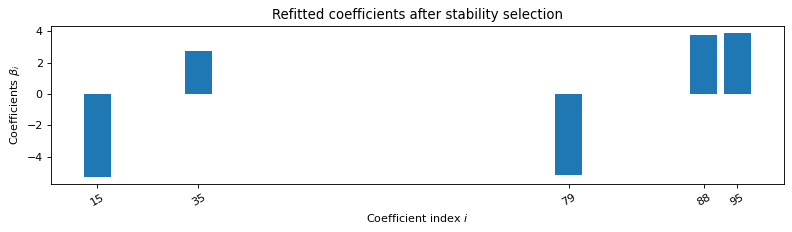


 LAMBDA FIXED : 
   Selected variables :  15    35    79    88    95    
   Running time :  0.007s

 PATH COMPUTATION : 
   Running time :  0.871s

 CROSS VALIDATION : 
   Selected variables :  15    35    79    88    95    
   Running time :  0.174s

 STABILITY SELECTION : 
   Selected variables :  15    35    79    88    95    
   Running time :  0.249s



In [22]:
problem1.solve()
print(problem1)
print(problem1.solution)
# plt.plot(problem1.solution.PATH.LAMBDAS, problem1.solution.PATH.BETAS[:, 0])
# plt.show()

problem2.solve()
print(problem2)
print(problem2.solution)


problem3.solve()
print(problem3)
# problem3.solution.CV.graphic(se_max = None)
print(problem3.solution)



## Reset the numerical methods 

In [23]:
problem1.model_selection.PATHparameters.numerical_method = ' '
problem2.model_selection.PATHparameters.numerical_method = 'P-PDS'
problem3.model_selection.PATHparameters.numerical_method = 'DR'

problem1.model_selection.CVparameters.numerical_method = ' '
problem2.model_selection.CVparameters.numerical_method = ' '
problem3.model_selection.CVparameters.numerical_method = 'P-PDS' 

problem1.model_selection.StabSelparameters.numerical_method = ' '
problem2.model_selection.StabSelparameters.numerical_method = ' '
problem3.model_selection.StabSelparameters.numerical_method = ' '

problem3.model_selection.StabSelparameters.lam = 'theoretical'

problem1.model_selection.LAMfixedparameters.numerical_method = 'P-PDS'
problem2.model_selection.LAMfixedparameters.numerical_method = 'DR'
problem3.model_selection.LAMfixedparameters.numerical_method = 'Path-Alg'

problem1.model_selection.LAMfixedparameters.lam = 'theoretical'


problem1.formulation.e = ' '
problem2.formulation.e = ' '
problem3.formulation.e = ' '

## R3

In [24]:
problem1.formulation.concomitant = True
problem1.formulation.huber = False
problem1.formulation.classification = False

problem2.formulation.concomitant = True
problem2.formulation.huber = False
problem2.formulation.classification = False

problem3.formulation.concomitant = True
problem3.formulation.huber = False
problem3.formulation.classification = False

too many labels, there for the labels ['0'] have been deleted
 
 
FORMULATION: R3
 
MODEL SELECTION COMPUTED:  
     Path
     Cross Validation
     Stability selection
     Lambda fixed
 
LAMBDA FIXED PARAMETERS: 
     numerical_method = Path-Alg
     rescaled lam : True
     threshold = 0.173
     lam : theoretical
     theoretical_lam = 0.1628
 
PATH PARAMETERS: 
     numerical_method : Path-Alg
     lamin = 0.001
     Nlam = 50
      
     maximum active variables = 20
 
CROSS VALIDATION PARAMETERS: 
     numerical_method : Path-Alg
     one-SE method : True
     Nsubset = 5
     lamin = 0.001
     Nlam = 80
      
 
STABILITY SELECTION PARAMETERS: 
     numerical_method : Path-Alg
     method : first
     B = 50
     q = 10
     percent_nS = 0.5
     threshold = 0.7
     lamin = 0.01
     Nlam = 50



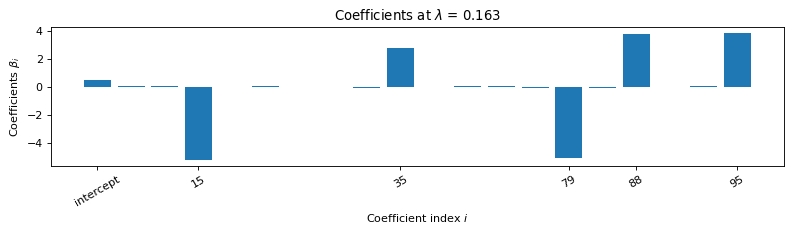

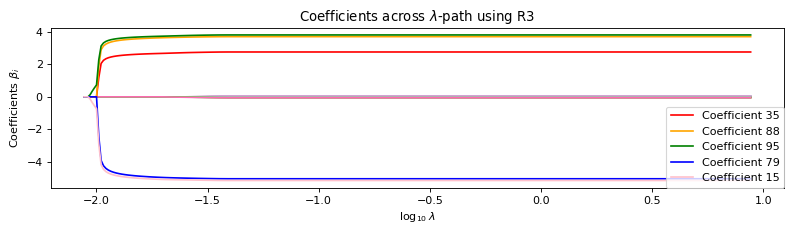

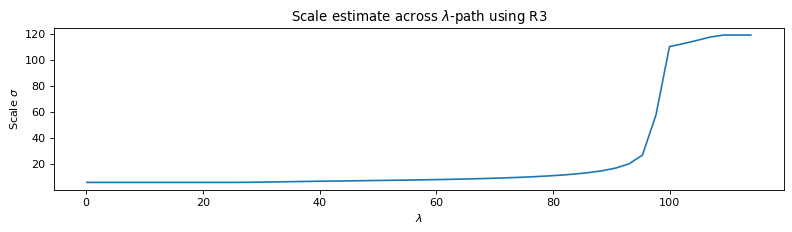

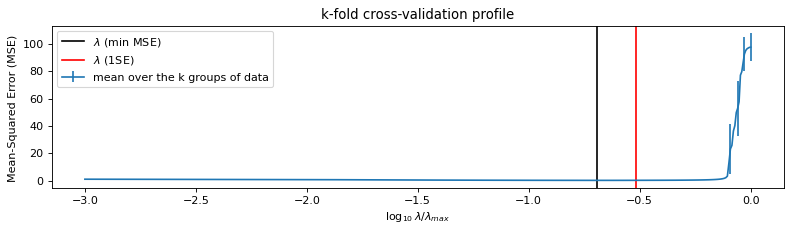

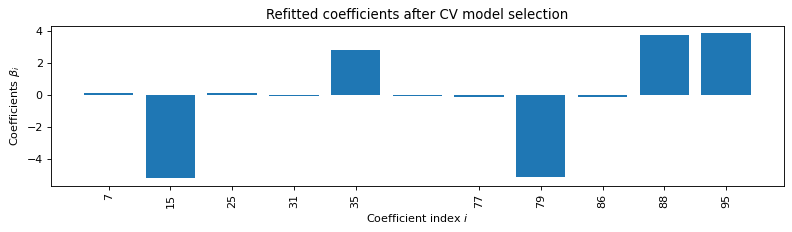

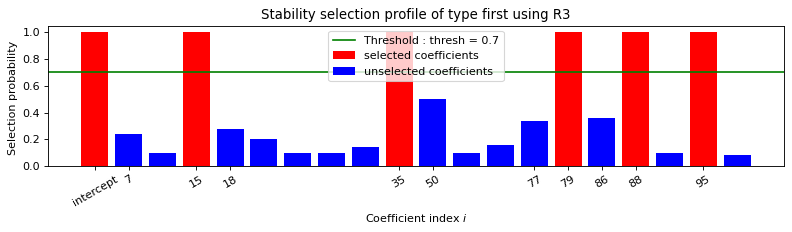

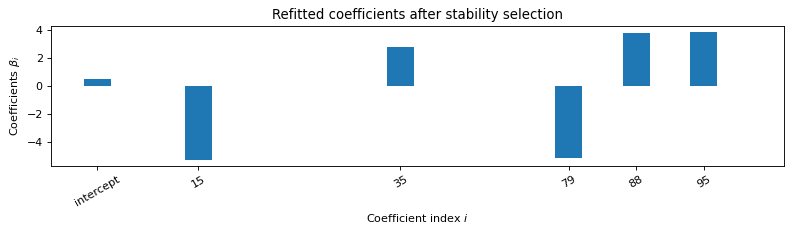


 LAMBDA FIXED : 
   Sigma  =  0.61
   Selected variables :  intercept    15    35    79    88    95    
   Running time :  0.006s

 PATH COMPUTATION : 
   There is also an intercept.  
   Running time :  0.007s

 CROSS VALIDATION : 
    Intercept : 0.4899300274827784
   Selected variables :  7    15    25    31    35    50    77    79    86    88    95    
   Running time :  0.186s

 STABILITY SELECTION : 
   Selected variables :  intercept    15    35    79    88    95    
   Running time :  0.149s

too many labels, there for the labels ['0'] have been deleted
 
 
FORMULATION: R3
 
MODEL SELECTION COMPUTED:  
     Path
     Cross Validation
     Stability selection
     Lambda fixed
 
LAMBDA FIXED PARAMETERS: 
     numerical_method = DR
     rescaled lam : True
     threshold = 0.189
     lam = 0.1
     theoretical_lam = 0.1628
 
PATH PARAMETERS: 
     numerical_method : Path-Alg
     lamin = 0.1
     Nlam = 50
      
 
CROSS VALIDATION PARAMETERS: 
     numerical_method : Path-Alg
 

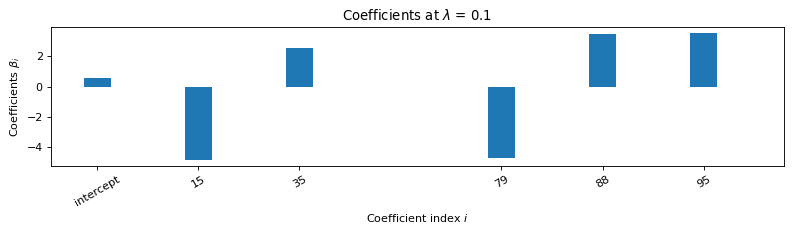

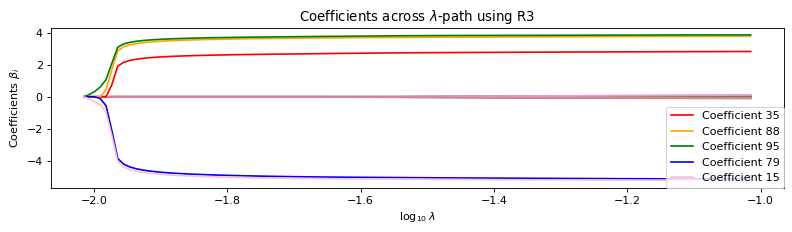

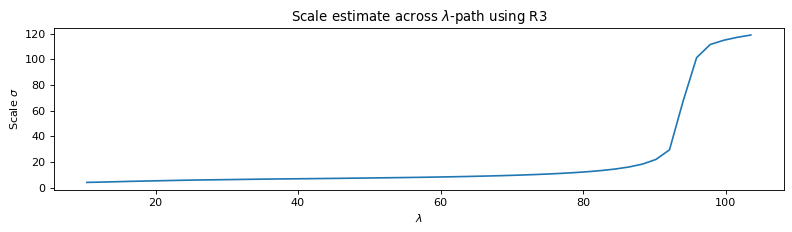

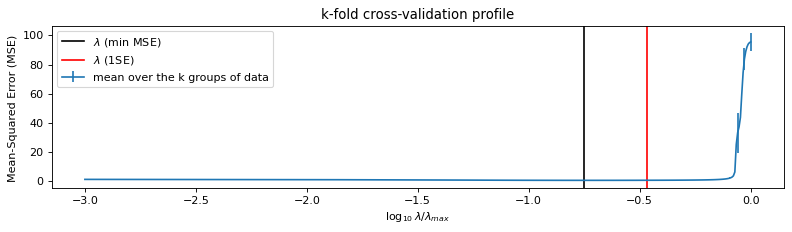

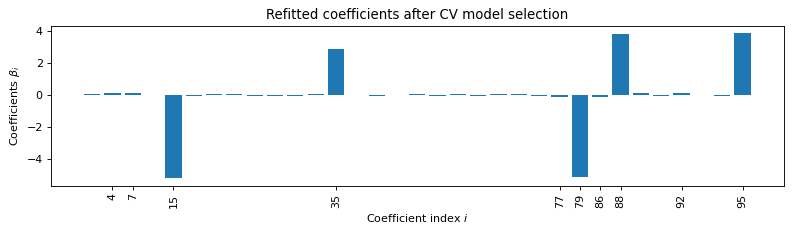

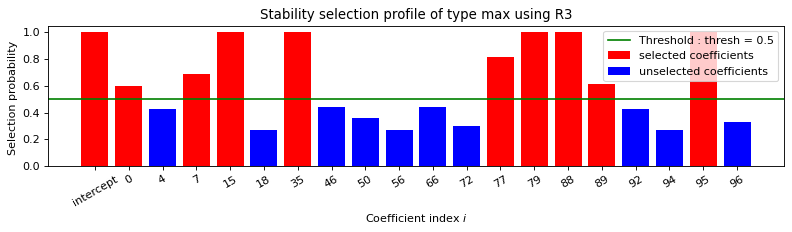

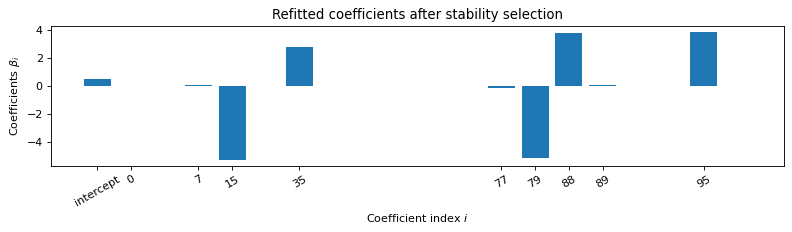


 LAMBDA FIXED : 
   Sigma  =  3.747
   Selected variables :  intercept    15    35    79    88    95    
   Running time :  3.86s

 PATH COMPUTATION : 
   There is also an intercept.  
   Running time :  0.013s

 CROSS VALIDATION : 
    Intercept : 0.501448772599121
   Selected variables :  0    4    7    11    15    18    25    27    29    30    31    33    35    48    50    55    57    58    60    63    66    69    70    77    79    86    88    89    91    92    93    94    95    
   Running time :  0.22s

 STABILITY SELECTION : 
   Selected variables :  intercept    0    7    15    35    77    79    88    89    95    
   Running time :  1.99s

 
 
FORMULATION: R3
 
MODEL SELECTION COMPUTED:  
     Path
     Cross Validation
     Stability selection
     Lambda fixed
 
LAMBDA FIXED PARAMETERS: 
     numerical_method = Path-Alg
     rescaled lam : True
     threshold = 0.276
     lam = 0.0
     theoretical_lam = 0.1628
 
PATH PARAMETERS: 
     numerical_method : DR
     lamin = 0.1
 

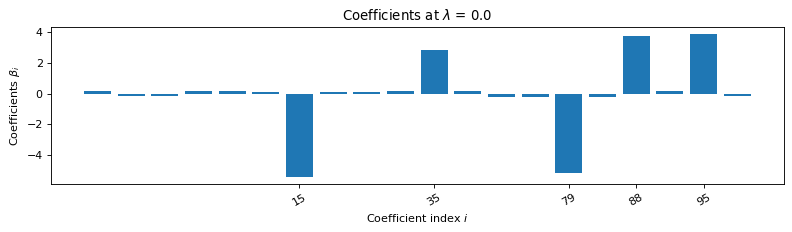

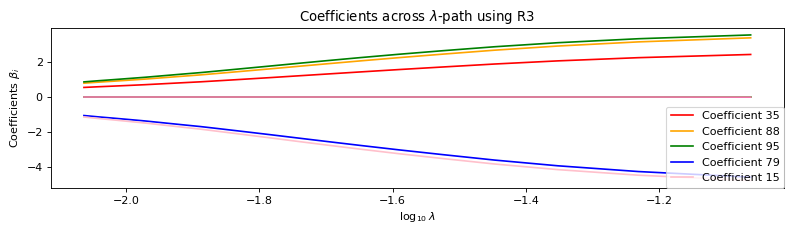

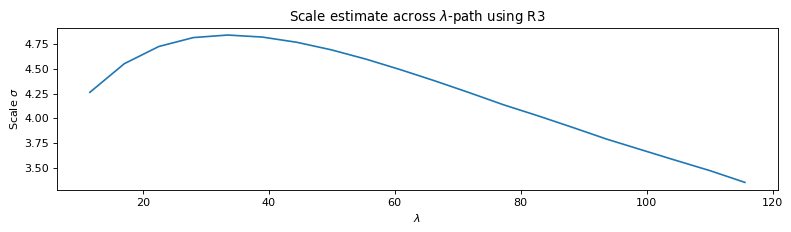

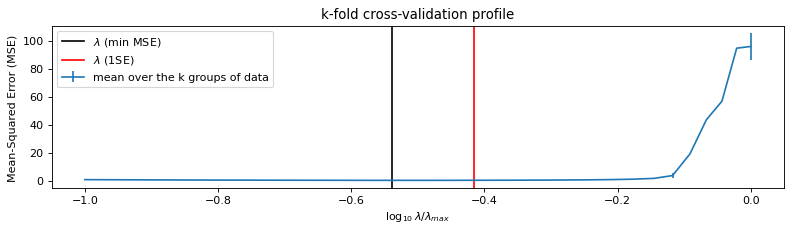

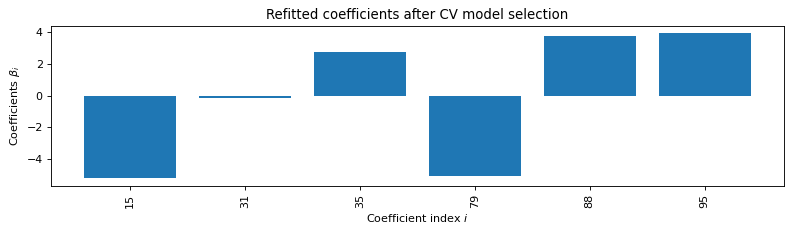

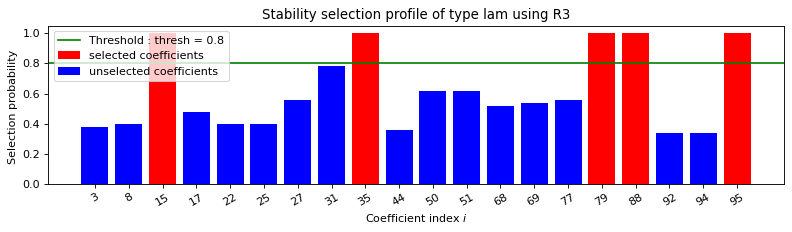

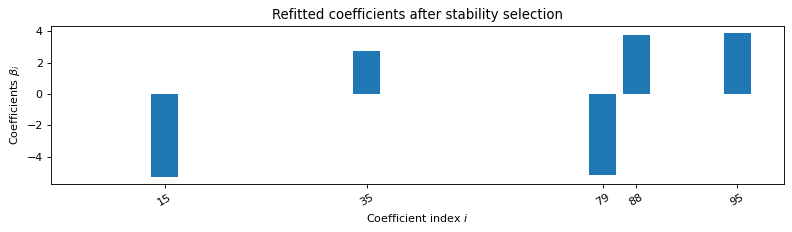


 LAMBDA FIXED : 
   Sigma  =  0.595
   Selected variables :  15    35    79    88    95    
   Running time :  0.002s

 PATH COMPUTATION : 
   Running time :  17.217s

 CROSS VALIDATION : 
   Selected variables :  15    31    35    79    88    95    
   Running time :  0.05s

 STABILITY SELECTION : 
   Selected variables :  15    35    79    88    95    
   Running time :  0.403s



In [25]:
problem1.solve()
print(problem1)
print(problem1.solution)


problem2.solve()
print(problem2)
print(problem2.solution)


problem3.solve()
print(problem3)
print(problem3.solution)


## Reset the numerical methods 

In [26]:
problem1.model_selection.PATHparameters.numerical_method = ' '
problem2.model_selection.PATHparameters.numerical_method = 'P-PDS'
problem3.model_selection.PATHparameters.numerical_method = 'DR'

problem1.model_selection.CVparameters.numerical_method = ' '
problem2.model_selection.CVparameters.numerical_method = ' '
problem3.model_selection.CVparameters.numerical_method = 'P-PDS' 

problem1.model_selection.StabSelparameters.numerical_method = ' '
problem2.model_selection.StabSelparameters.numerical_method = ' '
problem3.model_selection.StabSelparameters.numerical_method = ' '

problem3.model_selection.StabSelparameters.lam = 'theoretical'

problem1.model_selection.LAMfixedparameters.numerical_method = 'P-PDS'
problem2.model_selection.LAMfixedparameters.numerical_method = 'DR'
problem3.model_selection.LAMfixedparameters.numerical_method = 'Path-Alg'

problem1.model_selection.LAMfixedparameters.lam = 'theoretical'

problem1.formulation.e = ' '
problem2.formulation.e = ' '
problem3.formulation.e = ' '

## R4

In [27]:
problem1.formulation.concomitant = True
problem1.formulation.huber = True
problem1.formulation.classification = False

problem2.formulation.concomitant = True
problem2.formulation.huber = True
problem2.formulation.classification = False

problem3.formulation.concomitant = True
problem3.formulation.huber = True
problem3.formulation.classification = False

In [ ]:
problem1.solve()
print(problem1)
print(problem1.solution)


problem2.solve()
print(problem2)
print(problem2.solution)


problem3.solve()
print(problem3)
print(problem3.solution)


too many labels, there for the labels ['0'] have been deleted


## Reset the numerical methods 

In [ ]:
problem1.model_selection.PATHparameters.numerical_method = ' '
problem2.model_selection.PATHparameters.numerical_method = 'P-PDS'
problem3.model_selection.PATHparameters.numerical_method = 'DR'

problem1.model_selection.CVparameters.numerical_method = ' '
problem2.model_selection.CVparameters.numerical_method = ' '
problem3.model_selection.CVparameters.numerical_method = 'P-PDS' 

problem1.model_selection.StabSelparameters.numerical_method = ' '
problem2.model_selection.StabSelparameters.numerical_method = ' '
problem3.model_selection.StabSelparameters.numerical_method = ' '

problem3.model_selection.StabSelparameters.lam = 'theoretical'

problem1.model_selection.LAMfixedparameters.numerical_method = 'P-PDS'
problem2.model_selection.LAMfixedparameters.numerical_method = 'DR'
problem3.model_selection.LAMfixedparameters.numerical_method = 'Path-Alg'

problem1.model_selection.LAMfixedparameters.lam = 'theoretical'

## C1

In [ ]:
problem1.formulation.concomitant = False
problem1.formulation.huber = False
problem1.formulation.classification = True
problem1.data.y = np.sign(problem1.data.y)

problem2.formulation.concomitant = False
problem2.formulation.huber = False
problem2.formulation.classification = True
problem2.data.y = np.sign(problem2.data.y)

problem3.formulation.concomitant = False
problem3.formulation.huber = False
problem3.formulation.classification = True
problem3.data.y = np.sign(problem3.data.y)

In [ ]:
problem1.solve()
print(problem1)
#problem1.solution.CV.graphic(se_max = None)
print(problem1.solution)


problem2.solve()
print(problem2)
#problem2.solution.CV.graphic(se_max = None)
print(problem2.solution)


problem3.solve()
print(problem3)
#problem3.solution.CV.graphic(se_max = None)
print(problem3.solution)


## Reset the numerical methods 

In [ ]:
problem1.model_selection.PATHparameters.numerical_method = ' '
problem2.model_selection.PATHparameters.numerical_method = 'P-PDS'
problem3.model_selection.PATHparameters.numerical_method = 'DR'

problem1.model_selection.CVparameters.numerical_method = ' '
problem2.model_selection.CVparameters.numerical_method = ' '
problem3.model_selection.CVparameters.numerical_method = 'P-PDS' 

problem1.model_selection.StabSelparameters.numerical_method = ' '
problem2.model_selection.StabSelparameters.numerical_method = ' '
problem3.model_selection.StabSelparameters.numerical_method = ' '

problem3.model_selection.StabSelparameters.lam = 'theoretical'

problem1.model_selection.LAMfixedparameters.numerical_method = 'P-PDS'
problem2.model_selection.LAMfixedparameters.numerical_method = 'DR'
problem3.model_selection.LAMfixedparameters.numerical_method = 'Path-Alg'

problem1.model_selection.LAMfixedparameters.lam = 'theoretical'

## C2

In [ ]:
problem1.formulation.concomitant = False
problem1.formulation.huber = True
problem1.formulation.classification = True

problem2.formulation.concomitant = False
problem2.formulation.huber = True
problem2.formulation.classification = True

problem3.formulation.concomitant = False
problem3.formulation.huber = True
problem3.formulation.classification = True

In [ ]:
problem1.solve()
print(problem1)
print(problem1.solution)


problem2.solve()
print(problem2)
print(problem2.solution)


problem3.solve()
print(problem3)
print(problem3.solution)